# Cvičenie IV – Kalmanove filtre a priestorové dáta

-------------
## Kalmanov filter

Cieľom je pomocou Kalmanovho filtra odhadnúť skrytý stav $x_t$ z pozorovaných hodnôt $y_t$.

Pracuje v dvoch krokoch:

1. Predikcia – na základe predchádzajúceho odhadu predpovedá aktuálny stav.
2. Aktualizácia – po získaní nového pozorovania opraví predikciu pomocou Kalmanovho zisku.

Kalmanov zisk určuje, akú váhu priradíme novej pozorovanej hodnote v porovnaní s predchádzajúcou predikciou.

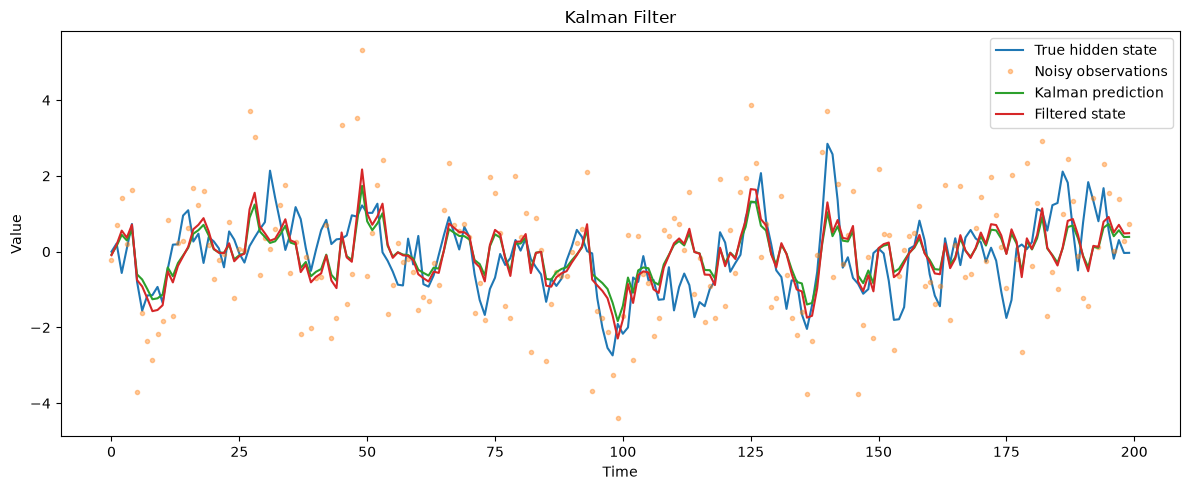

In [2]:
import numpy as np
import matplotlib.pyplot as plt
from statsmodels.tsa.statespace.kalman_filter import KalmanFilter

# 1. Parametre stavov?ho modelu
rng = np.random.default_rng(42)

n = 200
phi = 0.8
Q = 0.5
R = 2.0

# 2. Simul?cia skryt?ho AR(1) stavu
state = np.zeros(n)

for t in range(1, n):
    w_t = rng.normal(0, np.sqrt(Q))
    state[t] = phi * state[t - 1] + w_t

# 3. Vytvorenie za?umen?ch pozorovan?
v = rng.normal(0, np.sqrt(R), size=n)
observations = state + v

# 4. Vytvorenie a nastavenie Kalmanovho filtra
kf = KalmanFilter(k_endog=1, k_states=1)
kf.bind(observations)

kf.transition = np.array([[phi]])
kf.design = np.array([[1.0]])
kf.selection = np.array([[1.0]])
kf.state_cov = np.array([[Q]])
kf.obs_cov = np.array([[R]])

# Po?iato?n? stav je 0 a po?iato?n? rozptyl je stacion?rny rozptyl AR(1).
initial_state = np.array([0.0])
initial_covariance = np.array([[Q / (1 - phi**2)]])
kf.initialize_known(initial_state, initial_covariance)

# 5. Filtrovanie pozorovan?
results = kf.filter()
predicted_state = results.predicted_state[0, 1:]
filtered_state = results.filtered_state[0]

# 6. Porovnanie skuto?n?ho stavu, predikcie a filtrovan?ho odhadu
plt.figure(figsize=(12, 5))
plt.plot(state, label="True hidden state")
plt.plot(observations, ".", alpha=0.4, label="Noisy observations")
plt.plot(predicted_state, label="Kalman prediction")
plt.plot(filtered_state, label="Filtered state")
plt.xlabel("Time")
plt.ylabel("Value")
plt.title("Kalman Filter")
plt.legend()
plt.tight_layout()
plt.show()


--------
## Priestorové dáta

Kde sa javy dejú?

* Analýza hustoty zaľudnenia, šírenie infekcií, monitorovanie mobility či pohybu zveri.

Dva základné typy:

1. Vektory (Vector data): Body, čiary alebo polygóny
    
2. Rastre (Raster data)



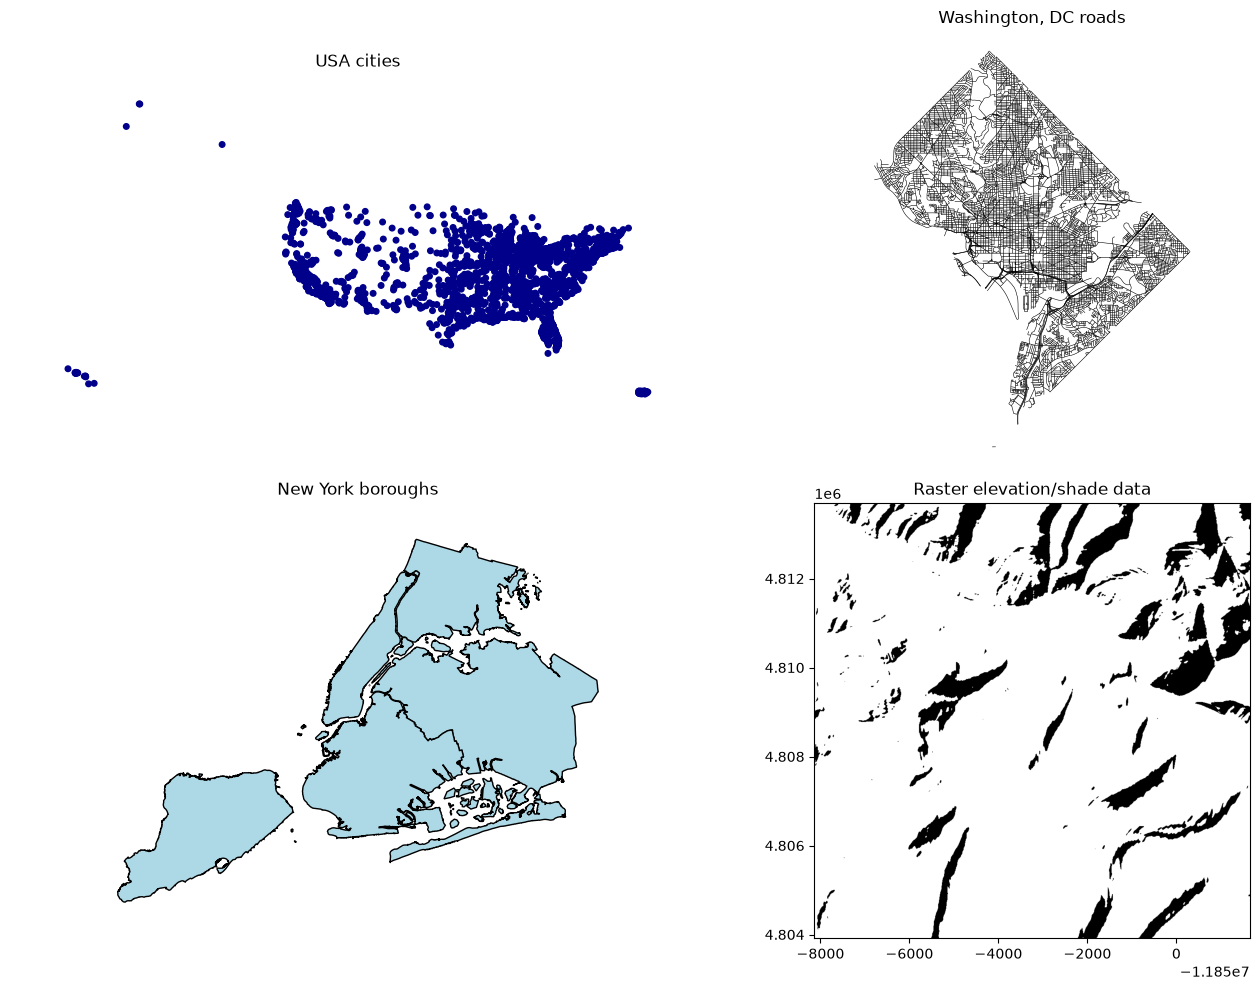

In [3]:
import matplotlib.pyplot as plt
import geopandas as gpd
import geoplot as gplt
import numpy as np
import rasterio
from rasterio.plot import show

# Na??tanie vektorov?ch datasetov z geoplot
usa_cities = gpd.read_file(gplt.datasets.get_path("usa_cities"))
dc_roads = gpd.read_file(gplt.datasets.get_path("dc_roads"))
nyc_boroughs = gpd.read_file(gplt.datasets.get_path("nyc_boroughs"))

# Na??tanie rastrov?ho datasetu
raster_url = (
    "https://github.com/rasterio/rasterio/raw/main/tests/data/shade.tif"
)

fig, axes = plt.subplots(2, 2, figsize=(14, 10))

# Mest? USA: body
gplt.pointplot(
    usa_cities,
    ax=axes[0, 0],
    s=4,
    color="darkblue",
)
axes[0, 0].set_title("USA cities")

# Cesty vo Washingtone DC: l?nie
dc_roads.plot(
    ax=axes[0, 1],
    color="black",
    linewidth=0.4,
)
axes[0, 1].set_title("Washington, DC roads")
axes[0, 1].set_axis_off()

# Mestsk? ?asti New Yorku: polyg?ny
gplt.polyplot(
    nyc_boroughs,
    ax=axes[1, 0],
    facecolor="lightblue",
    edgecolor="black",
)
axes[1, 0].set_title("New York boroughs")

# Rasterov? dataset
with rasterio.open(raster_url) as raster:
    show(raster, ax=axes[1, 1], cmap="gray")
axes[1, 1].set_title("Raster elevation/shade data")

plt.tight_layout()
plt.show()


* **Reprojekcia CRS**: 
  * Prevod súradníc z uhlových stupňov GPS (WGS 84) do metrického systému, aby sme mohli počítať reálne vzdialenosti a plochy v metroch.

* **Buffer (Obalová zóna)**:
  * Vytvorenie plošného polygónu okolo bodu, línie alebo plochy v zadanom polomere.

* **Intersection / Prienik**: 
  * Geometrické orezanie dvoch vrstiev, ktoré zachová iba územie, kde sa obe vrstvy navzájom prekrývajú.

* **Spatial Join**: 
  * Priestorový VLOOKUP, ktorý prepojí dve tabuľky na základe toho, či do seba ich geometrie v priestore fyzicky spadajú.

* **Change of Spatial Support (Zmena supportu)**: 
  * Zmena geometrickej mierky dát – napríklad agregácia tisícov izolovaných bodov do plošného súhrnu za celé polygóny.

* **MAUP (Modifiable Areal Unit Problem)**: 
  * Štatistické skreslenie, pri ktorom výsledky analýzy zásadne závisia od toho, aké veľké a aké tvary hraníc zvolíme pre agregáciu dát.


Borough CRS: EPSG:4326
Collision CRS: EPSG:4326
Manhattan area in EPSG:4326: 0.006307 square degrees
Manhattan area in EPSG:32618: 59.09 km?
Distance in EPSG:4326: 0.057064 degrees
Distance in EPSG:32618: 6.10 km
Land area inside 5 km buffer by borough:
 BoroName  area_km2
 Brooklyn  3.308073
Manhattan 33.828668
   Queens  7.799282
Accident counts by borough:
     BoroName  accident_count
        Bronx             582
     Brooklyn            2416
    Manhattan            1611
       Queens            2433
Staten Island             256


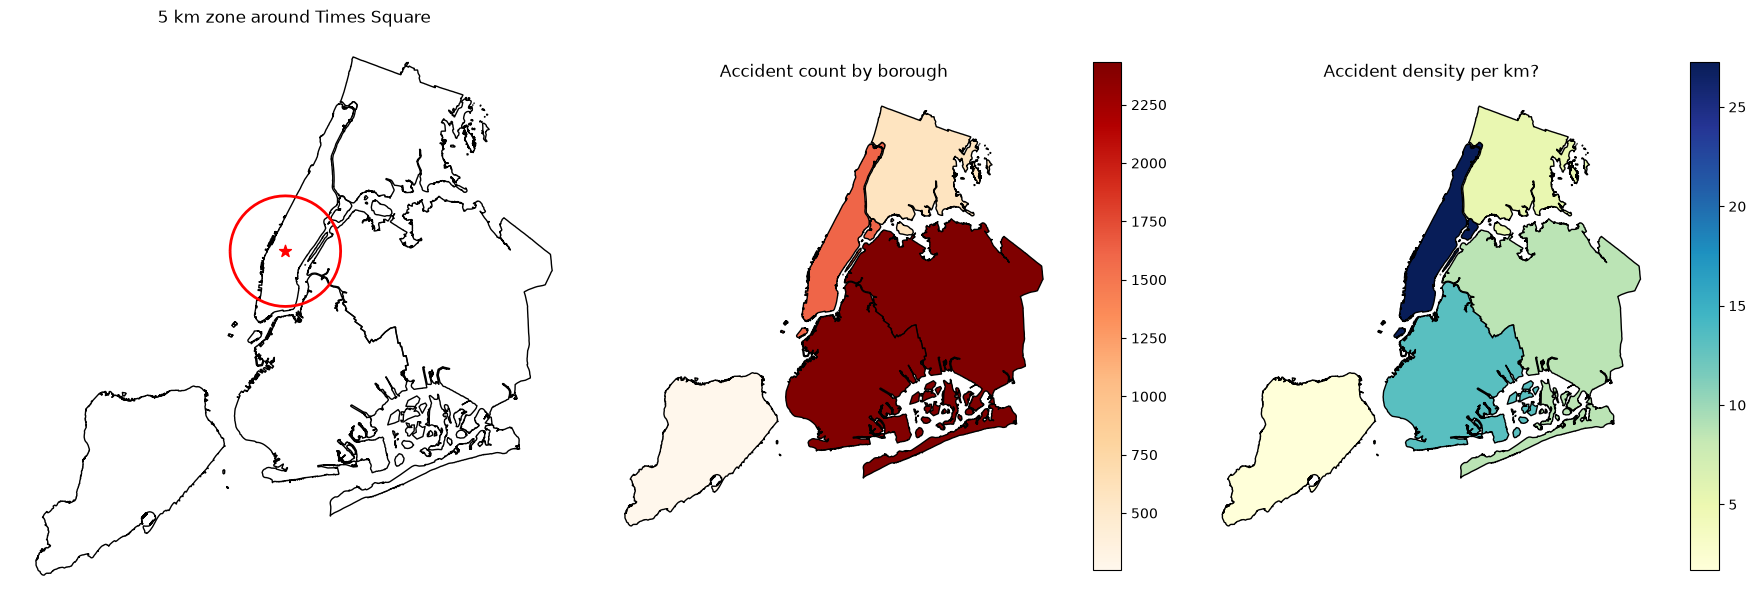

In [4]:
import matplotlib.pyplot as plt
import geopandas as gpd
import geoplot as gplt
import numpy as np

# Na??tanie d?t
nyc_boroughs = gpd.read_file(gplt.datasets.get_path("nyc_boroughs"))
nyc_collision_factors = gpd.read_file(
    gplt.datasets.get_path("nyc_collision_factors")
)

# Kontrola p?vodn?ho CRS
print("Borough CRS:", nyc_boroughs.crs)
print("Collision CRS:", nyc_collision_factors.crs)

# Reprojekcia do metrick?ho CRS UTM z?ny 18N
nyc_crs = "EPSG:32618"
nyc_boroughs_utm = nyc_boroughs.to_crs(nyc_crs)
nyc_collision_factors_utm = nyc_collision_factors.to_crs(nyc_crs)

# Porovnanie plochy Manhattanu v geografickom a metrickom CRS
manhattan = nyc_boroughs.loc[
    nyc_boroughs["BoroName"].eq("Manhattan")
].iloc[0]
manhattan_utm = nyc_boroughs_utm.loc[
    nyc_boroughs_utm["BoroName"].eq("Manhattan")
].iloc[0]

print(f"Manhattan area in EPSG:4326: {manhattan.geometry.area:.6f} square degrees")
print(f"Manhattan area in EPSG:32618: {manhattan_utm.geometry.area / 1e6:.2f} km?")

# Porovnanie vzdialenosti Times Square -> Wall Street
places = gpd.GeoDataFrame(
    {"name": ["Times Square", "Wall Street"]},
    geometry=gpd.points_from_xy(
        [-73.9855, -74.0090],
        [40.7580, 40.7060],
    ),
    crs="EPSG:4326",
)
places_utm = places.to_crs(nyc_crs)

distance_degrees = places.geometry.iloc[0].distance(places.geometry.iloc[1])
distance_m = places_utm.geometry.iloc[0].distance(places_utm.geometry.iloc[1])
print(f"Distance in EPSG:4326: {distance_degrees:.6f} degrees")
print(f"Distance in EPSG:32618: {distance_m / 1000:.2f} km")

# Vytvorenie 5 km z?ny okolo Times Square
times_square_utm = places_utm.iloc[[0]].copy()
times_square_buffer = times_square_utm.copy()
times_square_buffer["geometry"] = times_square_buffer.geometry.buffer(5000)

# Prienik z?ny s hranicami mestsk?ch ?ast?
land_inside_buffer = gpd.overlay(
    nyc_boroughs_utm,
    times_square_buffer[["geometry"]],
    how="intersection",
)
land_inside_buffer["area_km2"] = land_inside_buffer.geometry.area / 1e6

print("Land area inside 5 km buffer by borough:")
print(
    land_inside_buffer[["BoroName", "area_km2"]]
    .groupby("BoroName", as_index=False)
    .sum()
    .to_string(index=False)
)

# Priestorov? spojenie neh?d s mestsk?mi ?as?ami
collisions_with_borough = gpd.sjoin(
    nyc_collision_factors_utm,
    nyc_boroughs_utm[["BoroName", "geometry"]],
    how="left",
    predicate="within",
)

accident_counts = (
    collisions_with_borough
    .groupby("BoroName")
    .size()
    .rename("accident_count")
)

borough_summary = nyc_boroughs_utm[["BoroName", "geometry"]].copy()
borough_summary["area_km2"] = borough_summary.geometry.area / 1e6
borough_summary["accident_count"] = (
    borough_summary["BoroName"].map(accident_counts).fillna(0).astype(int)
)
borough_summary["accident_density"] = (
    borough_summary["accident_count"] / borough_summary["area_km2"]
)

print("Accident counts by borough:")
print(
    borough_summary[["BoroName", "accident_count"]]
    .sort_values("BoroName")
    .to_string(index=False)
)

# Vizualiz?cia z?ny, po?tov neh?d a hustoty neh?d
fig, axes = plt.subplots(1, 3, figsize=(18, 6))

nyc_boroughs_utm.plot(
    ax=axes[0],
    facecolor="none",
    edgecolor="black",
)
times_square_buffer.boundary.plot(
    ax=axes[0],
    color="red",
    linewidth=2,
)
times_square_utm.plot(
    ax=axes[0],
    color="red",
    marker="*",
    markersize=80,
)
axes[0].set_title("5 km zone around Times Square")
axes[0].set_axis_off()

borough_summary.plot(
    ax=axes[1],
    column="accident_count",
    cmap="OrRd",
    legend=True,
    edgecolor="black",
)
axes[1].set_title("Accident count by borough")
axes[1].set_axis_off()

borough_summary.plot(
    ax=axes[2],
    column="accident_density",
    cmap="YlGnBu",
    legend=True,
    edgecolor="black",
)
axes[2].set_title("Accident density per km?")
axes[2].set_axis_off()

plt.tight_layout()
plt.show()


## Priestorová autokorelácia

Miera toho, či sa podobné hodnoty v priestore zhlukujú (napr. bohaté štvrte vedľa bohatých), alebo sú rozmiestnené náhodne.

![Typy priestorovej autokorelácie](imgs/spatial_autocorrelation_types.png)


* **Negatívna** autokorelácia: Susedia vykazujú systematicky odlišné hodnoty – vysoké hodnoty sú obklopené nízkymi a naopak.
* **Žiadna** autokorelácia: Hodnoty sú rozmiestnené náhodne - priestorová nezávislosť.
* **Pozitívna** autokorelácia: Podobné hodnoty sa zhlukujú vedľa seba.

---

### Globálna priestorová autokorelácia a Globálne Moranovo $I$
Meria lineárnu závislosť medzi hodnotou v lokalite ($y$) a priemernou hodnotou u jej susedov ($Wy$):
* **$I > 0$ (do $+1$):** Pozitívna autokorelácia — podobné hodnoty sa zhlukujú (vysoké s vysokými, nízke s nízkymi).
* **$I \approx 0$:** Nulová autokorelácia — priestorová náhodnosť, hodnoty sú rozmiestnené nezávisle bez akéhokoľvek vzoru.
* **$I < 0$ (do $-1$, vľavo):** Negatívna autokorelácia — šachovnicové striedanie, kde susedia majú systematicky opačné hodnoty.

---

### Lokálna priestorová autokorelácia a Lokálne Moranovo $I$
Lokálne Moranovo $I$ sa počíta pre každú jednotlivú lokalitu, vďaka čomu identifikuje konkrétne územia, ktoré významne prispievajú k celkovej priestorovej autokorelácii. 

Zatrieďuje štatisticky významné lokality ($p < 0.05$) do 4 typov (kvadrantov):

* **HH (High-High) – Hotspot:** Vysoká hodnota obklopená vysokými hodnotami (napr. štvrť s vysokou kriminalitou uprostred iných nebezpečných štvrtí).
* **LL (Low-Low) – Coldspot:** Nízka hodnota obklopená nízkymi hodnotami (napr. pokojná, bezpečná rezidenčná zóna).
* **HL (High-Low) – Priestorový outlier:** Vysoká hodnota obklopená nízkymi hodnotami (ojedinelé problematické ohnisko v inak pokojnom regióne).
* **LH (Low-High) – Priestorový outlier:** Nízka hodnota obklopená vysokými hodnotami (bezpečná enkláva obklopená vysokou kriminalitou).


Observations: 49
Neighbors per observation: 8
Global Moran's I: 0.4367
Permutation p-value: 0.0010
Crime shows statistically significant spatial clustering.
Significant LISA clusters:
lisa_quadrant
HH    17
LL    10
HL     0
LH     1


c:\Users\Admin\Desktop\Master of AI\ASTD\04_exercises\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


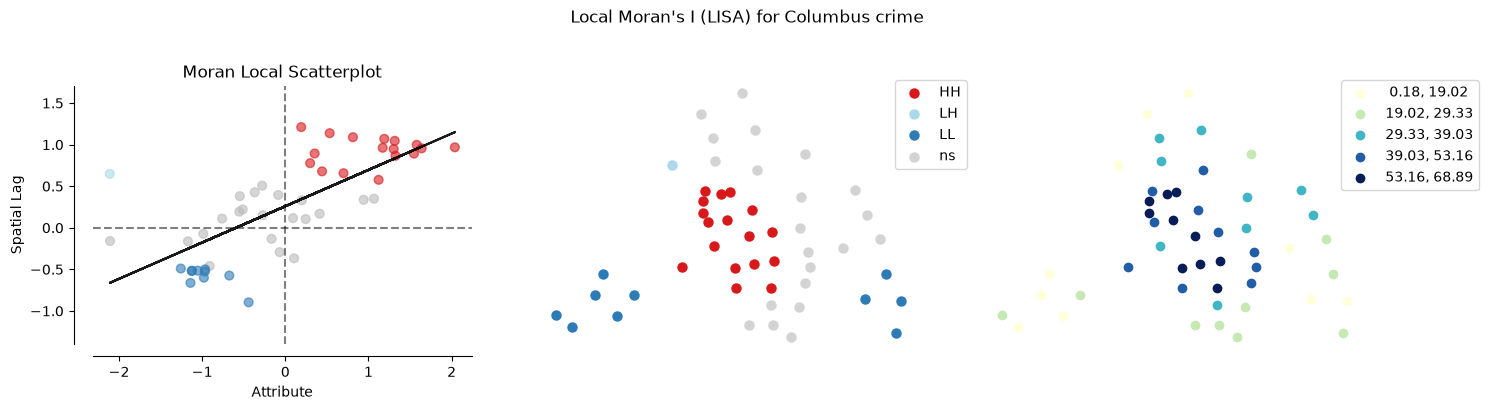

In [5]:
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import libpysal
from esda.moran import Moran, Moran_Local
from splot.esda import plot_local_autocorrelation

# 1. Na??tanie d?t mesta Columbus
DATA_URL = (
    "https://raw.githubusercontent.com/GeoDaCenter/GeoDaSpace/master/"
    "econometrics/examples/columbus.csv"
)

FULL_COLUMNS = [
    "AREA", "N", "COLUMBUS_", "COLUMBUS_I", "POLYID", "NEIG",
    "HOVAL", "INC", "CRIME", "OPEN", "PLUMB", "DISCBD", "X", "Y",
    "NSA", "NSB", "EW", "CP", "THOUS", "NEIGNO",
]

data = pd.read_csv(
    DATA_URL,
    skiprows=1,
    header=None,
    names=FULL_COLUMNS,
)

data["geometry"] = gpd.points_from_xy(data["X"], data["Y"])
data = gpd.GeoDataFrame(data, geometry="geometry")

# 2. KNN priestorov? v?hy pre 8 najbli???ch susedov
weights = libpysal.weights.KNN.from_dataframe(data, k=8)
weights.transform = "R"

print(f"Observations: {len(data)}")
print(f"Neighbors per observation: {weights.k}")

# 3. Glob?lne Moranovo I pre kriminalitu
moran = Moran(data["CRIME"], weights, permutations=999)
print(f"Global Moran's I: {moran.I:.4f}")
print(f"Permutation p-value: {moran.p_sim:.4f}")

if moran.p_sim < 0.05:
    print("Crime shows statistically significant spatial clustering.")
else:
    print("There is not enough evidence of spatial clustering in crime.")

# 4. Lok?lne Moranovo I a LISA vizualiz?cia
moran_local = Moran_Local(data["CRIME"], weights, permutations=999)

# q: 1=HH, 2=LH, 3=LL, 4=HL
quadrant_labels = {1: "HH", 2: "LH", 3: "LL", 4: "HL"}
data["lisa_quadrant"] = [
    quadrant_labels[q] if p < 0.05 else "Not significant"
    for q, p in zip(moran_local.q, moran_local.p_sim)
]

print("Significant LISA clusters:")
print(
    data.loc[data["lisa_quadrant"] != "Not significant", "lisa_quadrant"]
    .value_counts()
    .reindex(["HH", "LL", "HL", "LH"], fill_value=0)
    .to_string()
)

plot_local_autocorrelation(
    moran_local,
    data,
    "CRIME",
    p=0.05,
    figsize=(15, 4),
)
plt.suptitle("Local Moran's I (LISA) for Columbus crime", y=1.02)
plt.tight_layout()
plt.show()


## Priestorové modely: SLX, SAR, SEM a SDM

Keď OLS regresia vykazuje priestorovú autokoreláciu v rezíduách, nasadzujeme priestorové modely. Každý však rieši odlišný vecný mechanizmus:

| Model | Priestorová zložka | Mechanizmus | Kedy použiť |
| :--- | :--- | :--- | :--- | 
| **OLS** | Žiadna | Predpokladá, že rezíduá sú nezávislé. | Keď rezíduá nevykazujú priestorovú autokoreláciu (susedia sa neovplyvňujú). |
| **SLX** *(Spatial Lag of X)* | $WX$ (lagované prediktory) | K bežným vysvetľujúcim premenným ($X$) pridáva do regresie aj ich priestorové lagy u susedov ($WX$) | Pri lokálnom prelievaní vlastností susedov (napr. bohatstvo susedov vplýva na moju lokalitu). |
| **SAR** *(Spatial Lag)* | $Wy$ (lagovaný výsledok) | Do modelu pridáva priestorový lag samotnej závislej premennej ($Wy$). Analógia k autoregresným modelom (AR) v časových radoch. | Na rozdiel od SLX sa tu vplyvy neobmedzujú len na susedov, ale vďaka spätnej väzbe sa šíria cez celý systém  |
| **SEM** *(Spatial Error Model)* | $Wu$ (lagovaná chyba) | Nepozorované vplyvy a šoky sú priestorovo závislé. | Keď priestorovú štruktúru spôsobujú vynechané nepozorované faktory alebo spoločné šoky. |
| **SDM** *(Spatial Durbin Model)* | $Wy$ aj $WX$ | Používa sa spätná väzba medzi výsledkami aj charakteristiky susedov. | Keď pôsobí šírenie výsledku ($Wy$) aj vplyv charakteristík susedov ($WX$) súčasne. |



Prítomnosť priestorovej autokorelácie možno overiť Moranovým testom aplikovaným na rezíduá štandardnej OLS regresie. Tento všeobecný test nás však iba upozorní na existenciu priestorovej závislosti, ale neurčuje, ktorý konkrétny model zvoliť. Pre model s priestorovým lagom prediktorov (SLX) neexistuje špeciálny test; overuje sa klasickým $F$-testom lineárnych obmedzení porovnávajúcim model s lagmi $WX$ a bez nich.

Pre voľbu medzi modelom s priestorovým lagom výsledku (SAR) a modelom s priestorovou chybou (SEM) slúžia špecializované testy Lagrangeových multiplikátorov (LM testy), ktoré sa vyhodnocujú po odhade OLS. Ak je štatisticky významný iba klasický test LM(lag), volíme model SAR (priestorový lag). V opačnom prípade, ak je významný iba LM(error), je správnou voľbou model SEM (priestorová chyba).

### Postup výberu priestorového modelu

1. **Odhadneme OLS s diagnostikou**:
   - Ak **Moranovo I rezíduí nie je signifikantné** (\(p \geq 0.05\)) → nemáme dostatok dôkazov o priestorovej autokorelácii. **OLS môže byť postačujúci**.
   - Ak **je signifikantné** (\(p < 0.05\)) → rezíduá vykazujú priestorovú autokoreláciu a pomocou **LM testov** skúmame vhodný priestorový model.

2. **Rozhodovací strom podľa LM testov:**
   - **Ani jeden LM test nie je signifikantný** → OLS zostáva vhodným kandidátom.
   - **Signifikantný iba LM (lag)** → preferujeme **SAR** (priestorové oneskorenie \(Wy\)).
   - **Signifikantný iba LM (error)** → preferujeme **SEM** (priestorová chyba \(W\varepsilon\)).
   - **Signifikantné sú OBA** → skúmame **robustné LM testy**:
     - **Signifikantný iba Robust LM-lag** → preferujeme **SAR**.
     - **Signifikantný iba Robust LM-error** → preferujeme **SEM**.
     - **Oba robustné testy sú signifikantné** → zvážime komplexnejší priestorový model. Pri zjednodušenom výbere možno porovnať pôvodné LM testy a uprednostniť model s nižšou \(p\)-hodnotou.
     - **Ani jeden robustný test nie je signifikantný** → výsledok je nejednoznačný.

3. **Overenie vhodnosti vybraného modelu:**
   - Porovnáme AIC modelov OLS, SAR a SEM.
   - Skontrolujeme, či sa priestorová autokorelácia rezíduí znížila alebo odstránila.
   - Posúdime ekonomickú interpretáciu zvoleného modelu.


In [6]:
from spreg import OLS

# Premenn? CRIME je z?visl?; INC a HOVAL s? vysvet?uj?ce premenn?.
y = data[["CRIME"]].to_numpy()
X = data[["INC", "HOVAL"]].to_numpy()

ols = OLS(
    y,
    X,
    w=weights,
    spat_diag=True,
    moran=True,
    name_y="CRIME",
    name_x=["INC", "HOVAL"],
    name_w="KNN_8_row_standardized",
    name_ds="Columbus crime data",
)

print(ols.summary)

# Diagnostika: (statistika, p-hodnota) alebo (I, z-hodnota, p-hodnota).
moran_res = ols.moran_res
lm_lag = ols.lm_lag
lm_error = ols.lm_error
rlm_lag = ols.rlm_lag
rlm_error = ols.rlm_error

moran_res_p = float(moran_res[2])
lm_lag_p = float(lm_lag[1])
lm_error_p = float(lm_error[1])
rlm_lag_p = float(rlm_lag[1])
rlm_error_p = float(rlm_error[1])

print(f"Moran's I of OLS residuals: {moran_res[0]:.4f}")
print(f"Moran residual p-value: {moran_res_p:.6f}")
print(f"LM-lag p-value: {lm_lag_p:.6f}")
print(f"LM-error p-value: {lm_error_p:.6f}")
print(f"Robust LM-lag p-value: {rlm_lag_p:.6f}")
print(f"Robust LM-error p-value: {rlm_error_p:.6f}")

if moran_res_p >= 0.05:
    selected_model = "OLS"
elif rlm_lag_p < 0.05 and rlm_error_p >= 0.05:
    selected_model = "SAR"
elif rlm_error_p < 0.05 and rlm_lag_p >= 0.05:
    selected_model = "SEM"
elif lm_lag_p < 0.05 and lm_error_p >= 0.05:
    selected_model = "SAR"
elif lm_error_p < 0.05 and lm_lag_p >= 0.05:
    selected_model = "SEM"
else:
    selected_model = "Ambiguous: compare SAR and SEM using AIC and residual diagnostics"

print(f"Recommended model: {selected_model}")


REGRESSION RESULTS
------------------

SUMMARY OF OUTPUT: ORDINARY LEAST SQUARES
------------------------------------------------------------------------------------
Data set            :Columbus crime data
Weights matrix      :KNN_8_row_standardized
Dependent Variable  :       CRIME                Number of Observations:          49
Mean dependent var  :     35.1298                Number of Variables   :           3
S.D. dependent var  :     16.7321                Degrees of Freedom    :          46
R-squared           :      0.5525
Adjusted R-squared  :      0.5330
Sum squared residual:     6014.21                F-statistic           :     28.3918
Sigma-square        :     130.744                Prob(F-statistic)     :   9.315e-09
S.E. of regression  :      11.434                Log likelihood        :    -187.374
Sigma-square ML     :     122.739                Akaike info criterion :     380.749
S.E of regression ML:     11.0788                Schwarz criterion     :     386.424



c:\Users\Admin\Desktop\Master of AI\ASTD\04_exercises\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


## Priestorová krížová validácia a predikcia so SAR modelom

Priestorovo blízke pozorovania často vykazujú podobné hodnoty v dôsledku priestorovej autokorelácie. Náhodné delenie preto môže viesť k príliš optimistickému odhadu predikčnej schopnosti modelu na geograficky nepozorovaných územiach. - Spatial Data Leakage.

Riešením je priestorová bloková krížová validácia:
1. Územie rozdelíme do ucelených geografických blokov (napr. 4 kvadranty mesta: NW, NE, SW, SE).
2. V každom kole natrénujeme model na 3 blokoch a otestujeme jeho predikčnú schopnosť na 4. (geograficky oddelenom) bloku.

Knižnica `spreg` neponúka štandardnú metódu `.predict()`, pretože predikcia priestorového autoregresného modelu nie je obyčajné $X\beta$. Predikovaná hodnota závisí aj od priestorového spilloveru a väzieb na okolie:

$$\hat{y}_{test} = (I - \rho W_{TT})^{-1} \big(X_{test}\beta + \rho W_{TR} y_{train}\big)$$

* **$X_{test}\beta$**: Priamy vplyv vlastností lokality (príjem `INC`, hodnota domov `HOVAL`).
* **$\rho W_{TR} y_{train}$**: Priestorový vplyv, ktorý preteká cez hranicu z tréningového okolia, kde skutočné hodnoty $y_{train}$ poznáme.
* **$(I - \rho W_{TT})^{-1}$**: Priestorový multiplikátor vzájomného ovplyvňovania sa lokalít vnútri testovacieho územia.



ML_Lag

Test block: NW
rho: 0.4635
beta coefficients [const, INC, HOVAL]: [ 4.13770382e+01 -1.53033398e+00 -4.41245920e-03]
RMSE: 16.43
ML_Lag

Test block: NE
rho: 0.7072
beta coefficients [const, INC, HOVAL]: [27.82737053 -0.20238235 -0.44542202]
RMSE: 16.82
ML_Lag

Test block: SW
rho: 0.3755
beta coefficients [const, INC, HOVAL]: [46.85556665 -1.06713675 -0.2629863 ]
RMSE: 10.96
ML_Lag

Test block: SE
rho: 0.4931
beta coefficients [const, INC, HOVAL]: [39.66525651 -0.97081344 -0.24676842]
RMSE: 8.47


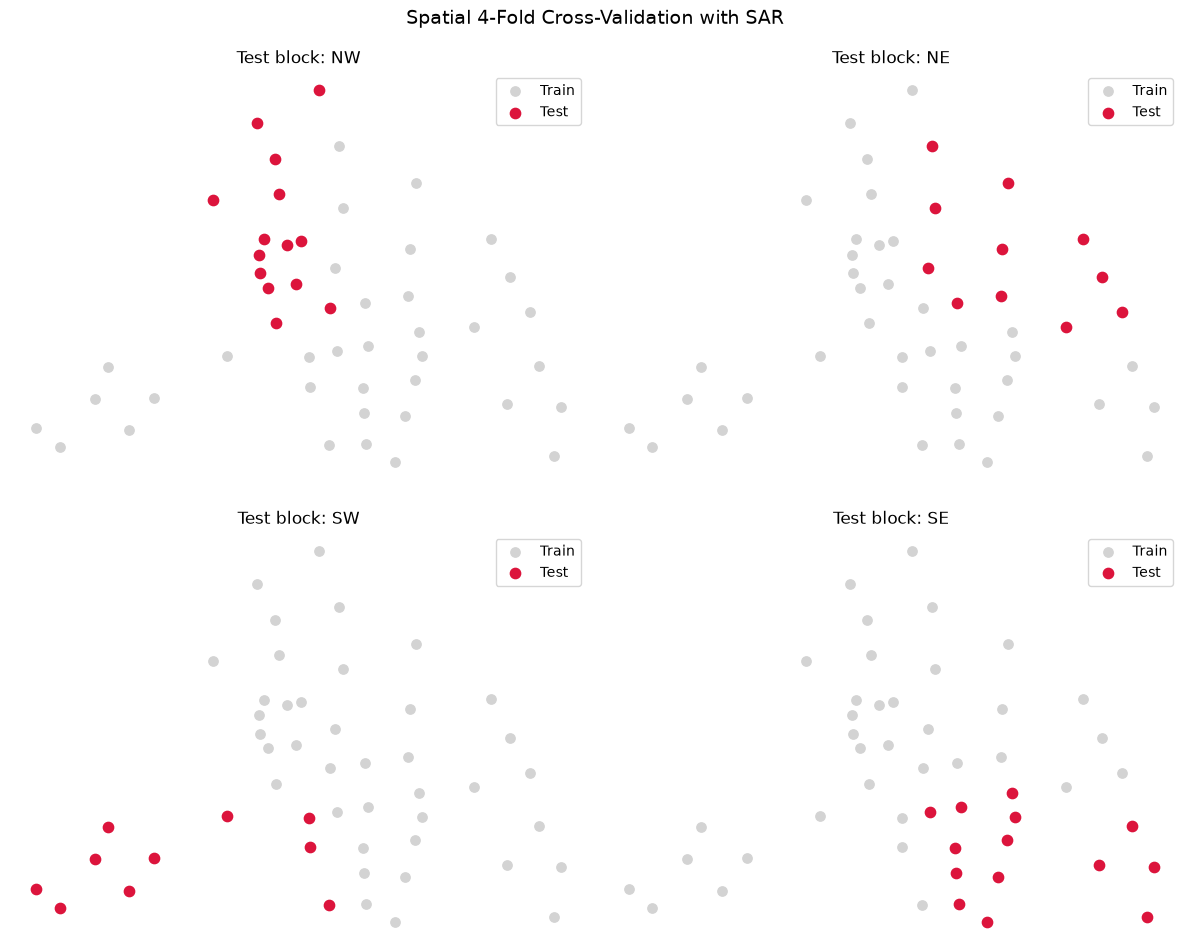


Fold RMSE:
test_block      rmse
        NW 16.433503
        NE 16.822181
        SW 10.959911
        SE  8.474964

Overall RMSE: 13.63


,POLYID,block,CRIME,pred_crime_sar
0,1,NW,15.73,29.398527
1,2,NW,18.80,27.209051
2,3,NE,30.63,37.009576
3,4,NW,32.39,52.455896
4,5,NE,50.73,50.042563
5,6,NE,26.07,32.032997
6,7,NW,0.18,50.878768
7,8,NW,38.43,47.335940
8,9,NE,30.52,34.894596
9,10,NE,34.00,-7.376086


In [7]:
import numpy as np
import pandas as pd
import geopandas as gpd
import matplotlib.pyplot as plt
import libpysal
from spreg import ML_Lag
from IPython.display import display

# Pomocn? funkcie pre predikciu OLS a SAR
def predict_ols(betas, X_test):
    X = np.column_stack([np.ones(len(X_test)), X_test])
    return (X @ betas).flatten()


def predict_sar(rho, betas, X_test, W_TT, W_TR, y_train):
    X = np.column_stack([np.ones(len(X_test)), X_test])
    direct_effect = (X @ betas).reshape(-1, 1)
    spillover_effect = rho * W_TR @ y_train.reshape(-1, 1)
    return np.linalg.solve(
        np.eye(len(X_test)) - rho * W_TT,
        direct_effect + spillover_effect,
    ).flatten()

# 1. Rozdelenie mesta na ?tyri geografick? bloky
med_x = data["X"].median()
med_y = data["Y"].median()


def assign_quadrant(row):
    if row["X"] >= med_x and row["Y"] >= med_y:
        return "NE"
    if row["X"] < med_x and row["Y"] >= med_y:
        return "NW"
    if row["X"] >= med_x and row["Y"] < med_y:
        return "SE"
    return "SW"


data = data.reset_index(drop=True)
data["block"] = data.apply(assign_quadrant, axis=1)
blocks = ["NW", "NE", "SW", "SE"]
data["pred_crime_sar"] = np.nan

# V?hy pre cel? mesto pou?ijeme na vz?ahy medzi testom a tr?ningom.
w_full = libpysal.weights.KNN.from_dataframe(data, k=4)
w_full.transform = "R"
W = w_full.sparse.tocsr()

fig, axes = plt.subplots(2, 2, figsize=(12, 10))
axes = axes.flatten()
fold_results = []

for ax, test_block in zip(axes, blocks):
    train = data[data["block"] != test_block].copy()
    test = data[data["block"] == test_block].copy()

    train_idx = train.index.to_numpy()
    test_idx = test.index.to_numpy()

    w_train = libpysal.weights.KNN.from_dataframe(train, k=4)
    w_train.transform = "R"

    y_train = train["CRIME"].to_numpy()
    X_train = train[["INC", "HOVAL"]].to_numpy()

    sar_fold = ML_Lag(
        y_train,
        X_train,
        w=w_train,
        method="full",
        name_y="CRIME",
        name_x=["INC", "HOVAL"],
        name_w="KNN_4_row_standardized",
        name_ds=f"Columbus training data without {test_block}",
    )

    # betas obsahuje intercept, koeficienty INC/HOVAL a na konci rho.
    rho = float(sar_fold.betas[-1, 0])
    betas = sar_fold.betas[:-1, 0]

    W_TT = W[test_idx, :][:, test_idx].toarray()
    W_TR = W[test_idx, :][:, train_idx].toarray()
    X_test = test[["INC", "HOVAL"]].to_numpy()

    y_pred = predict_sar(
        rho,
        betas,
        X_test,
        W_TT,
        W_TR,
        y_train,
    )
    data.loc[test_idx, "pred_crime_sar"] = y_pred

    rmse_fold = np.sqrt(np.mean((test["CRIME"].to_numpy() - y_pred) ** 2))
    fold_results.append({"test_block": test_block, "rmse": rmse_fold})

    print(f"\nTest block: {test_block}")
    print(f"rho: {rho:.4f}")
    print(f"beta coefficients [const, INC, HOVAL]: {betas}")
    print(f"RMSE: {rmse_fold:.2f}")

    data.loc[train_idx].plot(
        ax=ax,
        color="lightgray",
        markersize=45,
        label="Train",
    )
    data.loc[test_idx].plot(
        ax=ax,
        color="crimson",
        markersize=55,
        label="Test",
    )
    ax.set_title(f"Test block: {test_block}")
    ax.set_axis_off()
    ax.legend()

plt.suptitle(
    "Spatial 4-Fold Cross-Validation with SAR",
    fontsize=14,
)
plt.tight_layout()
plt.show()

# 8. Tabu?ka skuto?n?ch a predikovan?ch hodn?t
predictions_table = data[
    ["POLYID", "block", "CRIME", "pred_crime_sar"]
].copy()

overall_rmse = np.sqrt(
    np.mean((data["CRIME"] - data["pred_crime_sar"]) ** 2)
)

print("\nFold RMSE:")
print(pd.DataFrame(fold_results).to_string(index=False))
print(f"\nOverall RMSE: {overall_rmse:.2f}")
display(predictions_table.head(15))



#### Bonus 2B:

**Cieľ:** Preskúmať priestorovú závislosť dopravných nehôd medzi okrskami New Yorku a porovnať predikčnú schopnosť modelov OLS a SAR na geograficky oddelených testovacích dátach.

1. Príprava a agregácia dát podľa PSČ
  - Zoskupte dopravné nehody podľa poštových smerovacích čísel.
  - Pre každé PSČ vypočítajte celkový počet zaznamenaných nehôd.
  - Vytvorte cieľovú premennú podiel_np, ktorá vyjadruje podiel nehôd, pri ktorých bolo ako príčina uvedené nedanie prednosti v jazde.
  - Vytvorte vysvetľujúce premenné podiel_suv a podiel_taxiky, ktoré vyjadrujú podiel nehôd, pri ktorých bolo ako prvé zaznamenané vozidlo uvedené SUV alebo taxík.
  - Do ďalšej analýzy zahrňte iba oblasti PSČ s minimálne 8 zaznamenanými nehodami.
  - Pre každé PSČ vypočítajte priemernú zemepisnú šírku a dĺžku zaznamenaných nehôd a vytvorte bodový GeoDataFrame so súradnicovým systémom EPSG:4326. 
  - Rozdeľte PSČ podľa geografickej polohy na približne 80 % tréningových a 20 % testovacích pozorovaní.
  - Ako testovaciu množinu vyberte 20 % najvýchodnejšie položených oblastí podľa zemepisnej dĺžky (lon)
      * použite gdf['lon'].quantile(0.80) na určenie hranice
  - Vykreslite obe množiny na mape New Yorku a farebne ich odlíšte.

2. Konštrukcia priestorovej váhovej matice a predikcia s OLS a SAR
  - Reprojektujte bodové dáta do metrického súradnicového systému EPSG:32618.
  - Pomocou libpysal.weights.KNN vytvorte maticu 5 najbližších susedov (k=5) osobitne pre tréningové dáta a celé územie.
  - Vykonajte riadkovú štandardizáciu (transform='R').
  - Odhadnite OLS model pomocou spreg.OLS a SAR model pomocou spreg.ML_Lag.
  - Pomocou pripravených funkcií predict_ols() a predict_sar() vypočítajte predikované hodnoty pre testovacie oblasti.
  - Porovnajte skutočné a predikované hodnoty v tabuľke a grafe.
  - Určte, ktorý model dosiahol nižšiu predikčnú chybu.

ZIP areas after filtering: 158
Training areas: 126
Test areas: 32
Longitude threshold: -73.84269


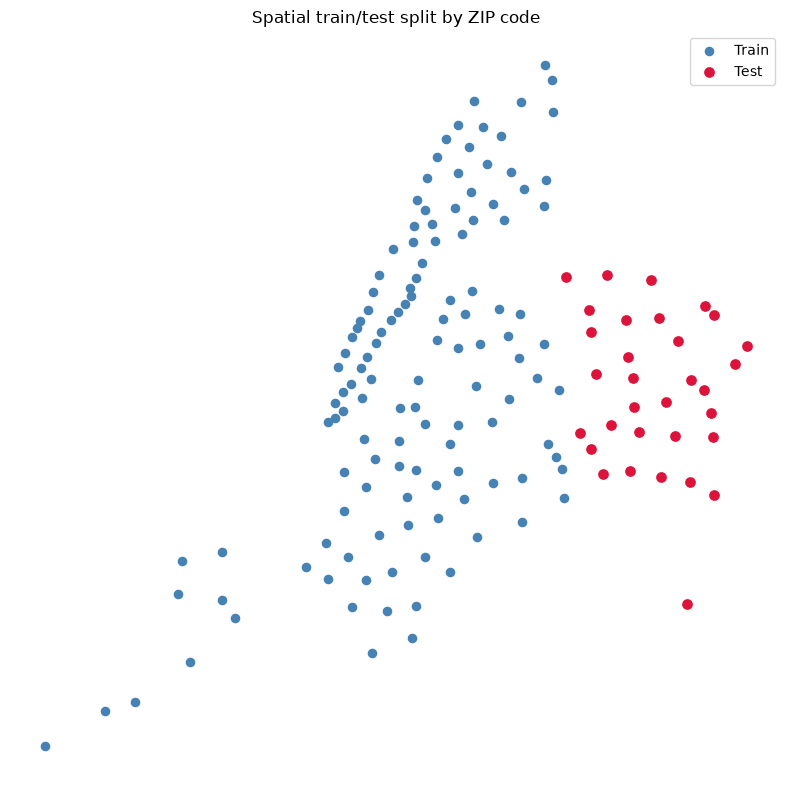

ML_Lag
OLS RMSE: 0.1176
SAR rho: 0.6028
SAR RMSE: 0.1102
Better model: SAR


c:\Users\Admin\Desktop\Master of AI\ASTD\04_exercises\.venv\Lib\site-packages\spreg\diagnostics.py:620: ComplexWarning: Casting complex values to real discards the imaginary part
  ci_result = sqrt(max_eigval / min_eigval)


,zip_code,podiel_np,pred_podiel_np_ols,pred_podiel_np_sar,error_ols,error_sar
67,11004,0.875000,0.709584,0.730635,0.165416,0.144365
112,11354,0.781250,0.773425,0.815801,0.007825,-0.034551
113,11355,0.851282,0.804523,0.848810,0.046759,0.002472
114,11356,0.829787,0.727934,0.802292,0.101853,0.027495
115,11357,0.882353,0.738267,0.787142,0.144086,0.095211
116,11358,0.851064,0.777848,0.813314,0.073216,0.037750
117,11360,0.944444,0.805020,0.810171,0.139425,0.134273
118,11361,0.769231,0.766845,0.786480,0.002385,-0.017249
119,11362,0.812500,0.766845,0.770617,0.045655,0.041883
120,11363,0.888889,0.754121,0.765015,0.134768,0.123873


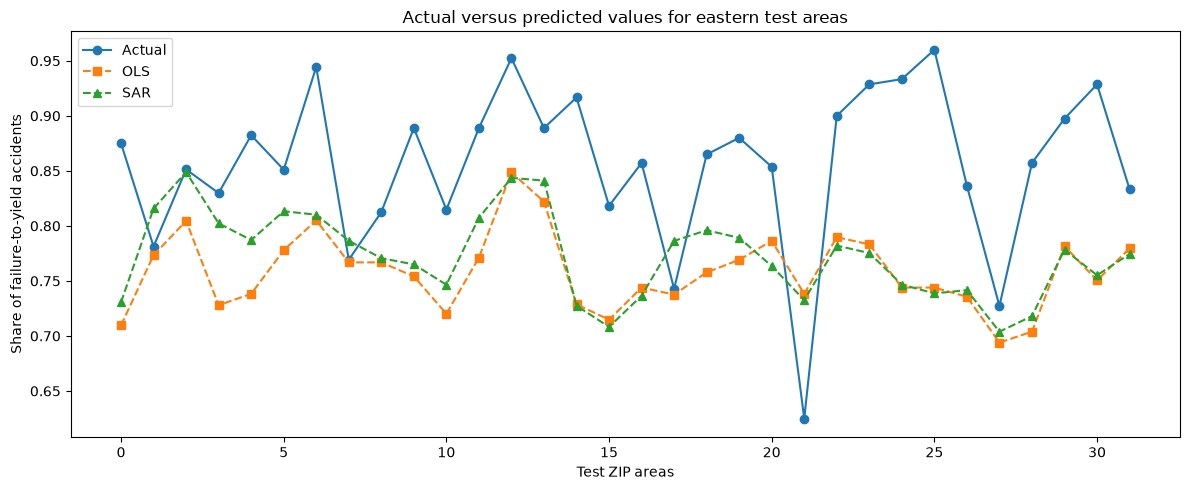

In [8]:
import numpy as np
import pandas as pd
import geopandas as gpd
import geoplot as gplt
import matplotlib.pyplot as plt
import libpysal
from spreg import OLS, ML_Lag
from IPython.display import display

# Na??tanie kol?znych d?t
collision_data = gpd.read_file(
    gplt.datasets.get_path("nyc_collision_factors")
).copy()

# Odstr?nenie z?znamov bez ZIP k?du alebo s?radn?c
collision_data = collision_data.dropna(
    subset=["ZIP CODE", "LONGITUDE", "LATITUDE"]
).copy()
collision_data["zip_code"] = collision_data["ZIP CODE"].astype(int).astype(str)

cause = collision_data["CONTRIBUTING FACTOR VEHICLE 1"].fillna("")
vehicle = collision_data["VEHICLE TYPE CODE 1"].fillna("")
collision_data["is_failure_to_yield"] = cause.eq("Failure to Yield Right-of-Way")
collision_data["is_suv"] = vehicle.eq("SPORT UTILITY / STATION WAGON")
collision_data["is_taxi"] = vehicle.eq("TAXI")

# Agreg?cia neh?d pod?a ZIP k?du
zip_summary = (
    collision_data.groupby("zip_code", as_index=False)
    .agg(
        total_accidents=("zip_code", "size"),
        failure_to_yield=("is_failure_to_yield", "sum"),
        suv_accidents=("is_suv", "sum"),
        taxi_accidents=("is_taxi", "sum"),
        lat=("LATITUDE", "mean"),
        lon=("LONGITUDE", "mean"),
    )
)

zip_summary["podiel_np"] = (
    zip_summary["failure_to_yield"] / zip_summary["total_accidents"]
)
zip_summary["podiel_suv"] = (
    zip_summary["suv_accidents"] / zip_summary["total_accidents"]
)
zip_summary["podiel_taxiky"] = (
    zip_summary["taxi_accidents"] / zip_summary["total_accidents"]
)

# Zachov?me iba ZIP k?dy s minim?lne 8 nehodami
zip_summary = zip_summary.loc[
    zip_summary["total_accidents"] >= 8
].reset_index(drop=True)

gdf = gpd.GeoDataFrame(
    zip_summary,
    geometry=gpd.points_from_xy(zip_summary["lon"], zip_summary["lat"]),
    crs="EPSG:4326",
)

# Najv?chodnej??ch 20 % ZIP oblast? tvor? geograficky oddelen? test
lon_threshold = gdf["lon"].quantile(0.80)
gdf["split"] = np.where(gdf["lon"] >= lon_threshold, "test", "train")
train = gdf[gdf["split"] == "train"].copy()
test = gdf[gdf["split"] == "test"].copy()

print(f"ZIP areas after filtering: {len(gdf)}")
print(f"Training areas: {len(train)}")
print(f"Test areas: {len(test)}")
print(f"Longitude threshold: {lon_threshold:.5f}")

# Mapa geografick?ho rozdelenia
fig, ax = plt.subplots(figsize=(9, 8))
train.plot(ax=ax, color="steelblue", markersize=35, label="Train")
test.plot(ax=ax, color="crimson", markersize=45, label="Test")
ax.set_title("Spatial train/test split by ZIP code")
ax.legend()
ax.set_axis_off()
plt.tight_layout()
plt.show()

# Reprojekcia do metrick?ho CRS
metric_gdf = gdf.to_crs("EPSG:32618")
metric_train = metric_gdf[metric_gdf["split"] == "train"].copy()
metric_test = metric_gdf[metric_gdf["split"] == "test"].copy()

feature_columns = ["podiel_suv", "podiel_taxiky"]
target_column = "podiel_np"
y_train = metric_train[target_column].to_numpy()
X_train = metric_train[feature_columns].to_numpy()
X_test = metric_test[feature_columns].to_numpy()

# KNN v?hy pre tr?ningov? d?ta a cel? ?zemie
w_train = libpysal.weights.KNN.from_dataframe(metric_train, k=5)
w_train.transform = "R"
w_full = libpysal.weights.KNN.from_dataframe(metric_gdf, k=5)
w_full.transform = "R"
W = w_full.sparse.tocsr()
train_idx = metric_train.index.to_numpy()
test_idx = metric_test.index.to_numpy()

# OLS model a predikcia
ols_model = OLS(
    y_train,
    X_train,
    w=w_train,
    name_y=target_column,
    name_x=feature_columns,
    name_w="KNN_5_row_standardized",
    name_ds="NYC ZIP collision data",
)
ols_betas = ols_model.betas[:, 0]
y_pred_ols = np.column_stack([
    np.ones(len(X_test)),
    X_test,
]) @ ols_betas

# SAR model a predikcia so spillover efektom z tr?ningov?ch oblast?
sar_model = ML_Lag(
    y_train,
    X_train,
    w=w_train,
    method="full",
    name_y=target_column,
    name_x=feature_columns,
    name_w="KNN_5_row_standardized",
    name_ds="NYC ZIP collision data",
)
rho = float(sar_model.betas[-1, 0])
sar_betas = sar_model.betas[:-1, 0]
W_TT = W[test_idx, :][:, test_idx].toarray()
W_TR = W[test_idx, :][:, train_idx].toarray()

design_test = np.column_stack([np.ones(len(X_test)), X_test])
direct_effect = (design_test @ sar_betas).reshape(-1, 1)
spillover_effect = rho * W_TR @ y_train.reshape(-1, 1)
y_pred_sar = np.linalg.solve(
    np.eye(len(X_test)) - rho * W_TT,
    direct_effect + spillover_effect,
).flatten()

# Porovnanie predikci?
predictions = metric_test[["zip_code", target_column]].copy()
predictions["pred_podiel_np_ols"] = y_pred_ols
predictions["pred_podiel_np_sar"] = y_pred_sar
predictions["error_ols"] = predictions[target_column] - predictions["pred_podiel_np_ols"]
predictions["error_sar"] = predictions[target_column] - predictions["pred_podiel_np_sar"]

rmse_ols = np.sqrt(np.mean(predictions["error_ols"] ** 2))
rmse_sar = np.sqrt(np.mean(predictions["error_sar"] ** 2))

print(f"OLS RMSE: {rmse_ols:.4f}")
print(f"SAR rho: {rho:.4f}")
print(f"SAR RMSE: {rmse_sar:.4f}")
print(
    "Better model: "
    + ("OLS" if rmse_ols < rmse_sar else "SAR")
)

display(predictions.head(15))

# Graf skuto?n?ch a predikovan?ch hodn?t
plot_data = predictions.reset_index(drop=True)
fig, ax = plt.subplots(figsize=(12, 5))
ax.plot(plot_data.index, plot_data[target_column], "o-", label="Actual")
ax.plot(plot_data.index, plot_data["pred_podiel_np_ols"], "s--", label="OLS")
ax.plot(plot_data.index, plot_data["pred_podiel_np_sar"], "^--", label="SAR")
ax.set_xlabel("Test ZIP areas")
ax.set_ylabel("Share of failure-to-yield accidents")
ax.set_title("Actual versus predicted values for eastern test areas")
ax.legend()
plt.tight_layout()
plt.show()
